# Multi-Fidelity Method Comparison: Forrester Function

Example is based on the 2007 paper "Multi-fidelity optimization via surrogate modelling" by Forrester, Sobester, and Keane.

In [ ]:
# Boilerplate for automatic reloading of modules on run and connecting to paths of local code.

%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
import torch
import numpy as np

from SurrogateModels import mfsnn, cokriging
import multi_fidelity_functions

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


Introduce the example function

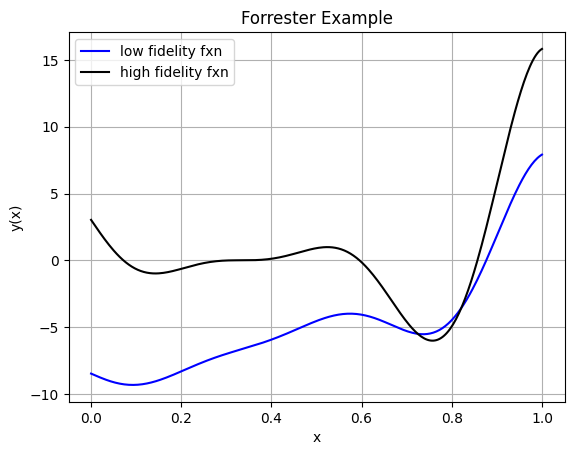

In [6]:
import multi_fidelity_functions
import matplotlib.pyplot as plt

mf_example = multi_fidelity_functions.ForresterExample()
mf_example.plot_functions_1d(name = mf_example.name)
plt.grid()
plt.show()

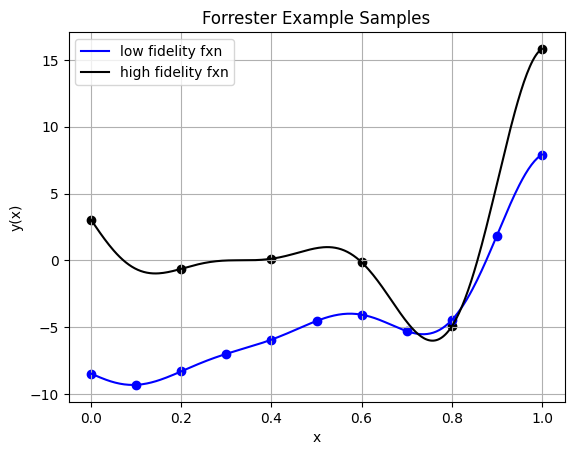

In [7]:
# Define the example function bounds and dimensions here
dim = mf_example.dimensions
xmin = mf_example.bounds[0][0]
xmax = mf_example.bounds[0][1]

n_lf = 11 # number of low fidelity points
n_hf = 6 # number of high fidelity points
n_test = 40 # number of test points

# Generate the analytical functions
hf_fxn = mf_example.high_fidelity
lf_fxn = mf_example.low_fidelity

X_lf = np.linspace(xmin,xmax,n_lf,dtype=np.float32).reshape(-1,1)
y_lf = lf_fxn(X_lf)

X_hf = np.linspace(xmin,xmax,n_hf,dtype=np.float32).reshape(-1,1)
y_hf = hf_fxn(X_hf)

X_test = np.linspace(xmin,xmax,n_test,dtype=np.float32).reshape(-1,1)
y_lf_test = lf_fxn(X_test)
y_hf_test = hf_fxn(X_test)

plot_name = mf_example.name + " Samples"

mf_example.plot_functions_1d(name = plot_name)

plt.figure(plot_name)
plt.title(plot_name)
plt.scatter(X_hf, y_hf, color = "black", label = "HF samples", marker = "o")
plt.scatter(X_lf, y_lf, color = "blue", label = "LF samples", marker = "o")

plt.grid()
plt.show()



## Multi-Fidelity Neural Network Fit

Using the method outlined by Meng and Karniadakis in the 2020 paper 
"A composite neural network that learns from multi-fidelity data: Application to function approximation and inverse PDE problems"
 generate a multi-fidelity function fit using the data defined from the analytical functions.

In [8]:
# Convert to tensors here
X_lf_tensor = torch.from_numpy(X_lf)
y_lf_tensor = torch.from_numpy(y_lf)

X_hf_tensor = torch.from_numpy(X_hf)
y_hf_tensor = torch.from_numpy(y_hf)

X_test_tensor = torch.from_numpy(X_test)
y_lf_test_tensor = torch.from_numpy(y_lf_test)
y_hf_test_tensor = torch.from_numpy(y_hf_test)

forrester_mfnn_model = mfsnn.MultiFidelityNN(
    X_lf=X_lf_tensor,
    y_lf=y_lf_tensor,
    X_lf_test=X_test_tensor,
    y_lf_test=y_lf_test_tensor,
    X_hf=X_hf_tensor,
    y_hf=y_hf_tensor,
    X_hf_test=X_test_tensor,
    y_hf_test=y_hf_test_tensor,
    lf_nn_dim=[20, 20, 20],
    hf_linear_nn_dim=[10],
    hf_nl_nn_dim=[10, 10],
    epochs_lf=100,
    epochs_mf=1000,
    lr_lf=0.001,
    wd_lf=0.000001,
    lr_mf=0.01,
    wd_mf=0.01,
)

tensor([[0.0000],
        [0.1000],
        [0.2000],
        [0.3000],
        [0.4000],
        [0.5000],
        [0.6000],
        [0.7000],
        [0.8000],
        [0.9000],
        [1.0000]])
----Progress Update----
Epoch: 0 

Training Error: 2.6748046875 

----Progress Update----
Epoch: 1 

Training Error: 2.029534339904785 

----Progress Update----
Epoch: 2 

Training Error: 1.1556180715560913 

----Progress Update----
Epoch: 3 

Training Error: 0.7783004641532898 

----Progress Update----
Epoch: 4 

Training Error: 0.647468626499176 

----Progress Update----
Epoch: 5 

Training Error: 0.5615299940109253 

----Progress Update----
Epoch: 6 

Training Error: 0.49597689509391785 

----Progress Update----
Epoch: 7 

Training Error: 0.45324909687042236 

----Progress Update----
Epoch: 8 

Training Error: 0.4186805486679077 

----Progress Update----
Epoch: 9 

Training Error: 0.324910044670105 

----Progress Update----
Epoch: 10 

Training Error: 0.2084941267967224 

----Progress Up

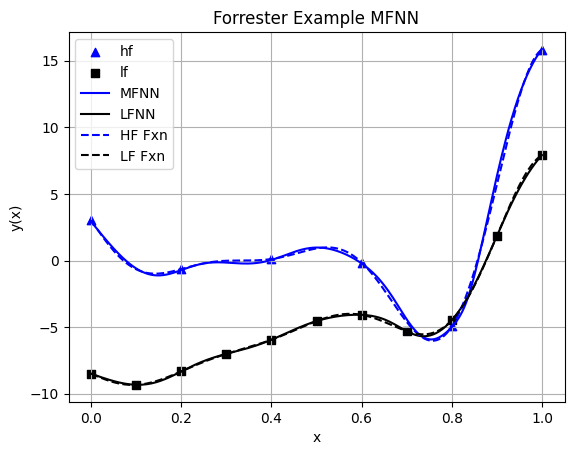

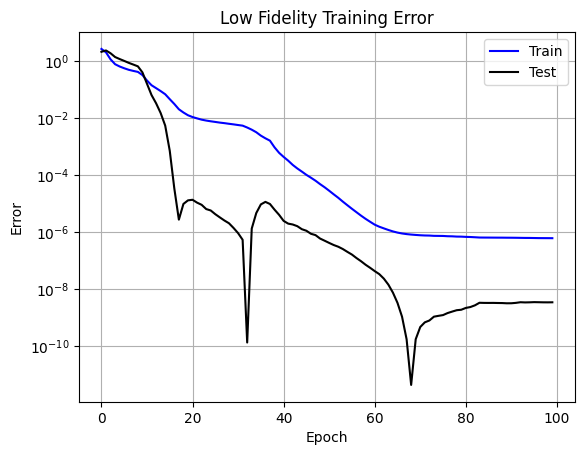

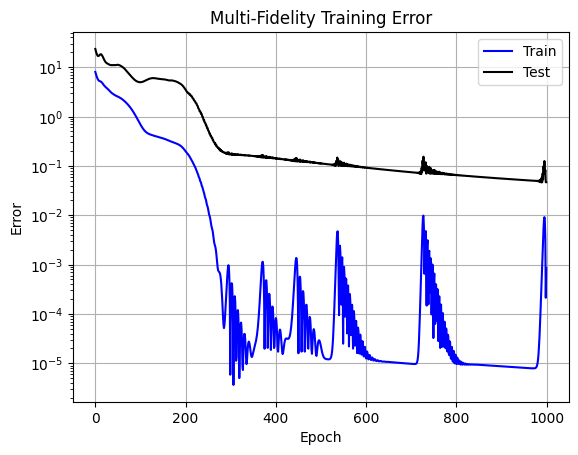

In [10]:
# Plot the results
plot_name = "Forrester Example MFNN"
forrester_mfnn_model.plot_data(plot_name)
X_check = np.linspace(0, 1.0, 300, endpoint=True,dtype=np.float32).reshape(-1,1)
X_check_tensor = torch.from_numpy(X_check)
forrester_mfnn_model.plot_model(X_check_tensor, name=plot_name, color="blue", label="MFNN")
forrester_mfnn_model.low_fidelity_nn.plot_model(X_check_tensor, name=plot_name, label="LFNN")
mf_example.plot_high_fidelity_data_1d(
    name=plot_name, color="blue", label="HF Fxn", linestyle="dashed"
)
mf_example.plot_low_fidelity_data_1d(
    name=plot_name, color="black", label="LF Fxn", linestyle="dashed"
)
plt.grid()
plt.show()

# Plot the model error
forrester_mfnn_model.low_fidelity_nn.plot_training_error("Low Fidelity Training Error")
plt.yscale("log")
plt.grid()
plt.show()
forrester_mfnn_model.high_fidelity_nn.plot_training_error("Multi-Fidelity Training Error")
plt.yscale("log")
plt.grid()
plt.show()

## Co-Kriging Function Fit

Utilizes the Co-Kriging function fit outlined in the Forrester 2007 paper.

In [12]:
forrester_cokriging_model = cokriging.CoKriging(X_lf,y_lf,X_hf,y_hf,True)

Optimization terminated successfully.
         Current function value: 4.877689
         Iterations: 21
         Function evaluations: 42
[16.08862305]
Optimization terminated successfully.
         Current function value: 3.296235
         Iterations: 18
         Function evaluations: 36
Optimization terminated successfully.
         Current function value: 11.254339
         Iterations: 32
         Function evaluations: 86
[1062.]


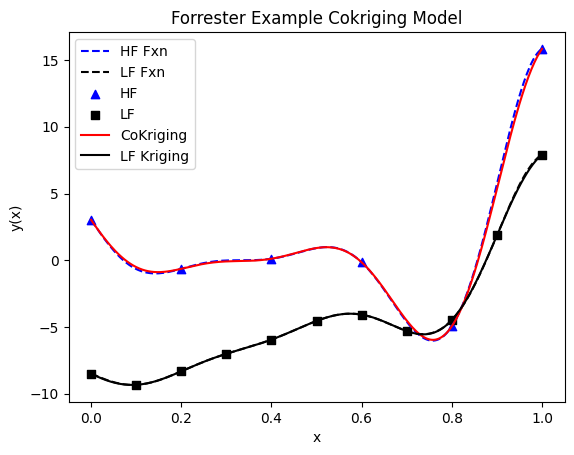

In [14]:
plot_name = mf_example.name + " Cokriging Model"

mf_example.plot_high_fidelity_data_1d(
    name=plot_name, color="blue", label="HF Fxn", linestyle="dashed"
)
mf_example.plot_low_fidelity_data_1d(
    name=plot_name, color="black", label="LF Fxn", linestyle="dashed"
)
forrester_cokriging_model.plot_data(
    name=plot_name,
    color_lf="black",
    color_hf="blue",
    label_hf="HF",
    label_lf="LF",
    marker_hf="^",
    marker_lf="s",
)
forrester_cokriging_model.plot_model(
    X_check, name=plot_name, color="red", label="CoKriging", linestyle="solid"
)
forrester_cokriging_model.kriging_lf.plot_model(
    X_check, name=plot_name, color="black", label="LF Kriging", linestyle="solid"
)
plt.show()

## Compare the Methods

Use a qualitative and qualitative approach to show data fit and relative error along the high-fidelity function

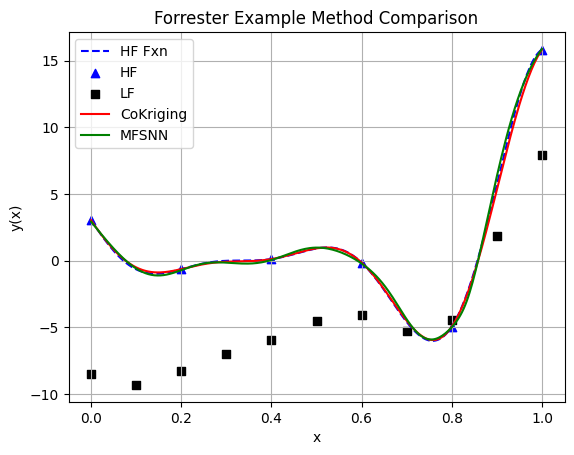

C:\Users\troyz\GitProjects\SurrogateModeling2\SurrogateModels\mf_model.py:59: RuntimeWarning: invalid value encountered in sqrt


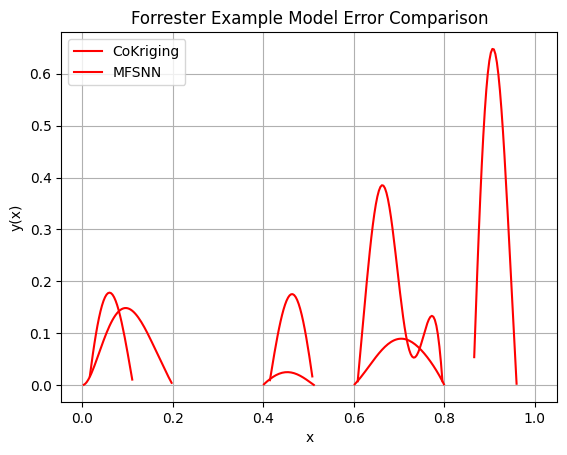

In [ ]:
plot_name = mf_example.name + " Method Comparison"

mf_example.plot_high_fidelity_data_1d(
    name=plot_name, color="blue", label="HF Fxn", linestyle="dashed"
)

forrester_cokriging_model.plot_data(
    name=plot_name,
    color_lf="black",
    color_hf="blue",
    label_hf="HF",
    label_lf="LF",
    marker_hf="^",
    marker_lf="s",
)
forrester_cokriging_model.plot_model(
    X_check, name=plot_name, color="red", label="CoKriging", linestyle="solid"
)

forrester_mfnn_model.plot_model(
    X_check_tensor, name=plot_name, color="green", label="MFSNN", linestyle="solid"
)
plt.grid()
plt.show()

plot_name = mf_example.name + " Model Error Comparison"

forrester_cokriging_model.plot_model_error(
    X_check, mf_example.high_fidelity, name=plot_name, color="black", label="CoKriging"
)
forrester_mfnn_model.plot_model_error(
    X_check_tensor, mf_example.high_fidelity, name=plot_name, color="blue", label="MFSNN"
)
plt.grid()
plt.show()